## 2.0 K-Means Clusteing [10 marks]

In [1]:
# Cell 1: Imports and dataset loading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Add these imports at the beginning
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
# Set style for plots
sns.set(style="whitegrid")

# Load dataset
file_path = "/home/rohitha/smai-2ass/Clustering_dataset.xlsx"
data = pd.read_excel(file_path, engine="openpyxl")

print("Original Dataset Shape:", data.shape)


Original Dataset Shape: (200, 5)


In [2]:
data.head()


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19.0,15.0,39.0
1,2,Male,21.0,NaN,81.0
2,3,Female,20.0,16.0,6.0
3,4,Female,23.0,16.0,77.0
4,5,Female,31.0,17.0,40.0


In [3]:
from sklearn.preprocessing import StandardScaler

# Fill numeric missing values with median
data["Annual Income (k$)"].fillna(data["Annual Income (k$)"].median(), inplace=True)
data["Spending Score (1-100)"].fillna(data["Spending Score (1-100)"].median(), inplace=True)
data["Age"].fillna(data["Age"].median(), inplace=True)

# Drop rows with missing Genre
data.dropna(subset=["Genre"], inplace=True)

# Encode Genre: Male = 0, Female = 1
data["Genre"] = data["Genre"].str.strip().map({"Male": 0, "Female": 1})

# Select numeric columns for clustering
numeric_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X_raw = data[numeric_cols].values  # raw data (before scaling)

# Apply StandardScaler
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

print("Before Scaling (first 5 rows):")
print(X_raw[:5])
print("\nAfter Scaling (first 5 rows):")
print(X[:5])


Before Scaling (first 5 rows):
[[19. 15. 39.]
 [21. 62. 81.]
 [20. 16.  6.]
 [23. 16. 77.]
 [31. 17. 40.]]

After Scaling (first 5 rows):
[[-1.44542338 -1.76255298 -0.43033695]
 [-1.30069453  0.04866736  1.20205853]
 [-1.37305896 -1.72401638 -1.71293341]
 [-1.15596569 -1.72401638  1.0465923 ]
 [-0.57705031 -1.68547978 -0.3914704 ]]


/tmp/ipykernel_16588/833001356.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data["Annual Income (k$)"].fillna(data["Annual Income (k$)"].median(), inplace=True)
/tmp/ipykernel_16588/833001356.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col

## 2.1 Implement a K-Means Class [6 marks]

In [4]:
# Cell 3: Custom KMeans Class
class KMeansClustering:
    """
    A simple implementation of K-Means clustering algorithm.
    """

    def __init__(self, k=5, max_iters=100, random_state=None):
        self.k = k
        self.max_iters = max_iters
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None

    def fit(self, X):
        np.random.seed(self.random_state)
        n_samples = X.shape[0]

        # Initialize centroids randomly
        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.centroids = X[random_indices]

        for _ in range(self.max_iters):
            # Assign clusters
            distances = self._compute_distances(X)
            self.labels_ = np.argmin(distances, axis=1)

            # Compute new centroids
            new_centroids = np.array([X[self.labels_ == j].mean(axis=0) for j in range(self.k)])

            # Stop if converged
            if np.allclose(self.centroids, new_centroids, rtol=1e-6):
                break
            self.centroids = new_centroids

    def predict(self, X):
        distances = self._compute_distances(X)
        return np.argmin(distances, axis=1)

    def getCost(self, X):
        distances = self._compute_distances(X)
        min_distances = np.min(distances, axis=1)
        return np.sum(min_distances ** 2)

    def _compute_distances(self, X):
        return np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)


In [5]:
# Cell 4: Use optimal k from analysis
optimal_k = 5  # Based on your elbow/silhouette analysis
kmeans = KMeansClustering(k=optimal_k, max_iters=100, random_state=42)
kmeans.fit(X)
labels = kmeans.labels_

In [6]:
# Cell 5: Plotting function
def plot_clusters(X, labels, centroids, feature_names, f1=1, f2=2, title="K-Means Clustering", username="kuluri.sarvani"):
    plt.figure(figsize=(8, 6))
    
    # Data points
    plt.scatter(X[:, f1], X[:, f2], c=labels, cmap="viridis", alpha=0.7, s=50)
    
    # Centroids
    plt.scatter(centroids[:, f1], centroids[:, f2], c="red", marker="X", s=200, label="Centroids")

    plt.title(title, fontsize=14)
    plt.xlabel(feature_names[f1], fontsize=12)
    plt.ylabel(feature_names[f2], fontsize=12)
    plt.legend()

    # Watermark
    plt.text(0.95, 0.95, username,
             ha='right', va='top',
             transform=plt.gca().transAxes,
             fontsize=10, color='gray', alpha=0.7)

    plt.show()


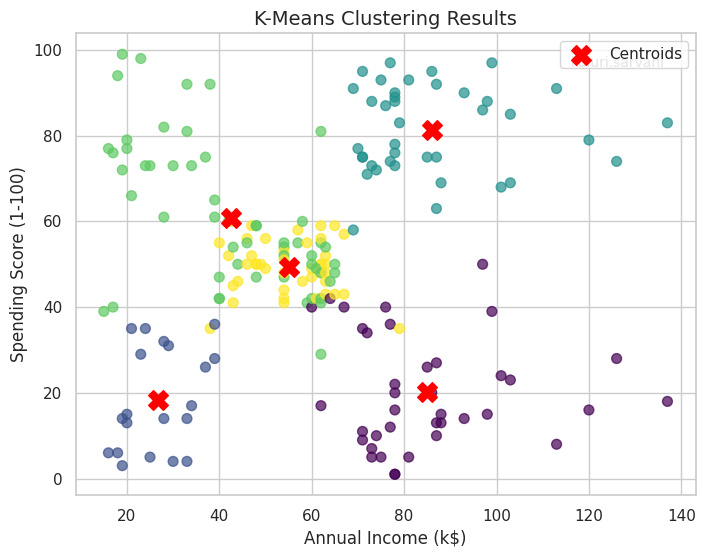

In [7]:
# Cell 6: Plot clustering results (CORRECTED)
def plot_clusters_fixed(X_scaled, labels, centroids_scaled, scaler, f1=1, f2=2, title="K-Means Clustering", username="kuluri.sarvani"):
    # Convert scaled data back to original scale for proper visualization
    X_original = scaler.inverse_transform(X_scaled)
    centroids_original = scaler.inverse_transform(centroids_scaled)
    
    plt.figure(figsize=(8, 6))
    
    # Plot using ORIGINAL scale data
    plt.scatter(X_original[:, f1], X_original[:, f2], c=labels, cmap="viridis", alpha=0.7, s=50)
    plt.scatter(centroids_original[:, f1], centroids_original[:, f2], c="red", marker="X", s=200, label="Centroids")

    plt.title(title, fontsize=14)
    
    feature_names = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
    plt.xlabel(feature_names[f1], fontsize=12)
    plt.ylabel(feature_names[f2], fontsize=12)
    plt.legend()
    # ADD WATERMARK HERE
    plt.text(0.95, 0.95, username,
             ha='right', va='top',
             transform=plt.gca().transAxes,
             fontsize=10, color='gray', alpha=0.7)

    # Watermark
    plt.text(0.95, 0.95, username,
             ha='right', va='top',
             transform=plt.gca().transAxes,
             fontsize=10, color='gray', alpha=0.7)

    plt.show()

# Use the fixed plotting function
plot_clusters_fixed(
    X, 
    labels, 
    kmeans.centroids,
    scaler,  # Pass the scaler to convert back to original scale
    f1=1,  # Annual Income
    f2=2,  # Spending Score
    title="K-Means Clustering Results",
    username="kuluri.sarvani"
)

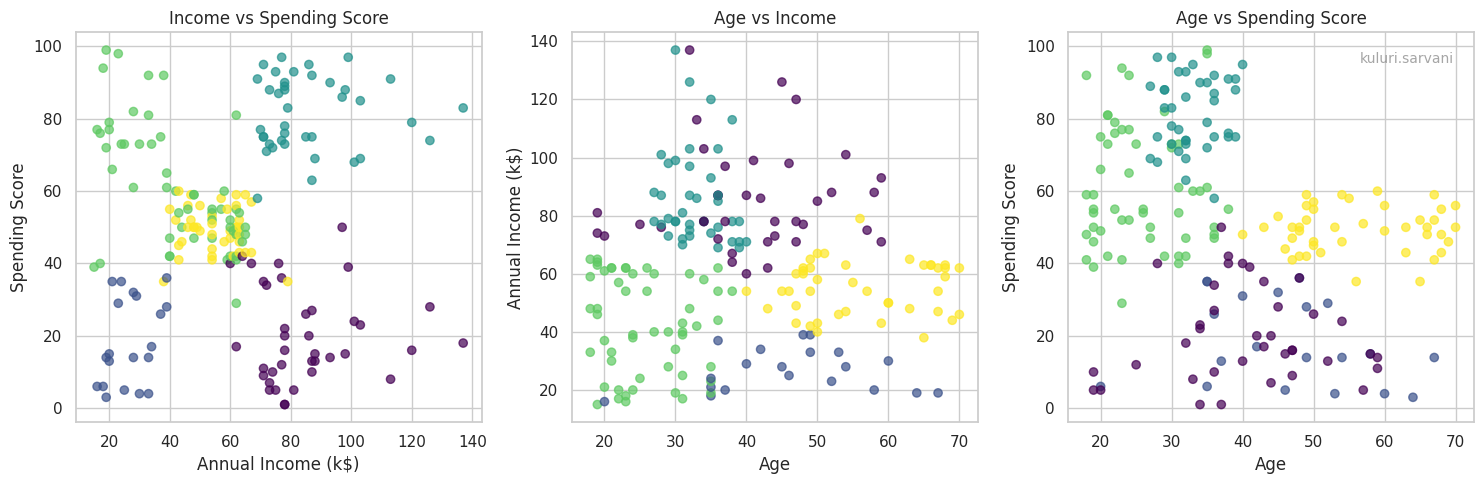

In [8]:
# Add this cell to understand the Age factor
def plot_3d_analysis(X_scaled, labels, scaler):
    X_original = scaler.inverse_transform(X_scaled)
    
    plt.figure(figsize=(15, 5))
    
    # Plot 1: Income vs Spending (what you currently see)
    plt.subplot(1, 3, 1)
    plt.scatter(X_original[:, 1], X_original[:, 2], c=labels, cmap="viridis", alpha=0.7)
    plt.title("Income vs Spending Score")
    plt.xlabel("Annual Income (k$)")
    plt.ylabel("Spending Score")
    
    # Plot 2: Age vs Income (the hidden dimension!)
    plt.subplot(1, 3, 2)
    plt.scatter(X_original[:, 0], X_original[:, 1], c=labels, cmap="viridis", alpha=0.7)
    plt.title("Age vs Income")
    plt.xlabel("Age")
    plt.ylabel("Annual Income (k$)")
    
    # Plot 3: Age vs Spending (another hidden view)
    plt.subplot(1, 3, 3)
    plt.scatter(X_original[:, 0], X_original[:, 2], c=labels, cmap="viridis", alpha=0.7)
    plt.title("Age vs Spending Score")
    plt.xlabel("Age")
    plt.ylabel("Spending Score")
    # ADD WATERMARK HERE
    plt.text(0.95, 0.95, "kuluri.sarvani",
             ha='right', va='top',
             transform=plt.gca().transAxes,
             fontsize=10, color='gray', alpha=0.7)
    
    plt.tight_layout()
    plt.show()

# Run this to see the full picture
plot_3d_analysis(X, labels, scaler)

## 2.2 Determine the Optimal Number of Clusters [4 marks]

### Elbow Method 

K=1, WCSS=582.00
K=2, WCSS=382.39
K=3, WCSS=288.48
K=4, WCSS=208.00
K=5, WCSS=170.27
K=6, WCSS=138.16
K=7, WCSS=122.71
K=8, WCSS=108.73
K=9, WCSS=96.79
K=10, WCSS=87.53


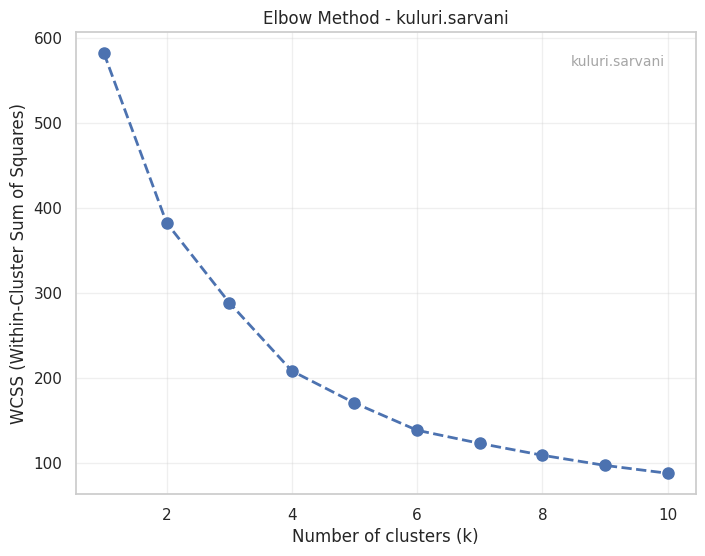

In [9]:
# Cell: Elbow Method using sklearn KMeans
wcss = []
K_range = range(1, 11)  # Try k = 1 to 10 (including k=1 for complete elbow)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)  # inertia_ is WCSS in sklearn
    print(f"K={k}, WCSS={kmeans.inertia_:.2f}")

# Plot
plt.figure(figsize=(8, 6))
plt.plot(K_range, wcss, marker="o", linestyle="--", linewidth=2, markersize=8)
plt.title("Elbow Method - kuluri.sarvani")
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.grid(True, alpha=0.3)

# Watermark
plt.text(0.95, 0.95, "kuluri.sarvani",
         ha='right', va='top',
         transform=plt.gca().transAxes,
         fontsize=10, color='gray', alpha=0.7)

plt.show()

#### Analysis of Elbow Method Results

Based on the WCSS values obtained:

| K | WCSS |
|---|------|
| 1 | 582.00 |
| 2 | 382.39 |
| 3 | 288.48 |
| 4 | 208.00 |
| 5 | 170.27 |
| 6 | 138.16 |
| 7 | 122.71 |
| 8 | 108.73 |
| 9 | 96.79 |
| 10 | 87.53 |

**Optimal Value of k According to Elbow Method:**

The "elbow" in the WCSS curve occurs around **k = 5 or k = 6**. Here's the analysis:

- **Sharp decrease**: From k=1 to k=4, there's a steep decline in WCSS (582.00 → 208.00)
- **Elbow point**: The rate of decrease slows significantly after k=5 (170.27) and k=6 (138.16)
- **Diminishing returns**: Beyond k=6, the WCSS continues to decrease but at a much slower rate

**Conclusion**: The optimal number of clusters according to the Elbow Method is **k = 5 or k = 6**, as this represents the best trade-off between minimizing within-cluster variance and avoiding over-segmentation of the data.

### Silhouette Method 

K=2, Silhouette Score=0.3240
K=3, Silhouette Score=0.3461
K=4, Silhouette Score=0.3827
K=5, Silhouette Score=0.4010
K=6, Silhouette Score=0.4061
K=7, Silhouette Score=0.3956
K=8, Silhouette Score=0.3907
K=6, Silhouette Score=0.4061
K=7, Silhouette Score=0.3956
K=8, Silhouette Score=0.3907
K=9, Silhouette Score=0.4014
K=10, Silhouette Score=0.4068
K=9, Silhouette Score=0.4014
K=10, Silhouette Score=0.4068


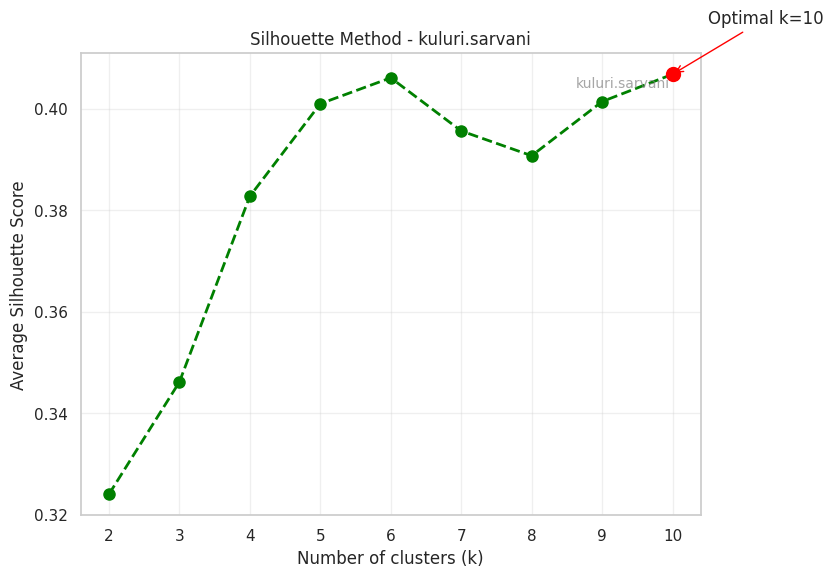


Optimal number of clusters based on Silhouette Score: k = 10


In [10]:
# Cell: Silhouette Method using sklearn KMeans
silhouette_scores = []
K_range = range(2, 11)  # Silhouette score requires k >= 2

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)
    print(f"K={k}, Silhouette Score={score:.4f}")

# Plot
plt.figure(figsize=(8, 6))
plt.plot(K_range, silhouette_scores, marker="o", linestyle="--", color="green", linewidth=2, markersize=8)
plt.title("Silhouette Method - kuluri.sarvani")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Average Silhouette Score")
plt.grid(True, alpha=0.3)

# Find and highlight the optimal k
optimal_k = K_range[np.argmax(silhouette_scores)]
optimal_score = max(silhouette_scores)
plt.scatter(optimal_k, optimal_score, color='red', s=100, zorder=5)
plt.annotate(f'Optimal k={optimal_k}', 
             xy=(optimal_k, optimal_score), 
             xytext=(optimal_k+0.5, optimal_score+0.01),
             arrowprops=dict(arrowstyle='->', color='red'))

# Watermark
plt.text(0.95, 0.95, "kuluri.sarvani",
         ha='right', va='top',
         transform=plt.gca().transAxes,
         fontsize=10, color='gray', alpha=0.7)

plt.show()

print(f"\nOptimal number of clusters based on Silhouette Score: k = {optimal_k}")

#### Analysis of Silhouette Method Results

Based on the Silhouette scores obtained:

| K | Silhouette Score |
|---|------------------|
| 2 | 0.3240 |
| 3 | 0.3461 |
| 4 | 0.3827 |
| 5 | 0.4010 |
| 6 | 0.4061 |
| 7 | 0.3956 |
| 8 | 0.3907 |
| 9 | 0.4014 |
| 10 | 0.4068 |

**Optimal Value of k According to Silhouette Method:**

The value of k that **maximizes the silhouette score is k = 10** with a score of **0.4068**.

However, it's important to note that k = 6 (score = 0.4061) is very close to the maximum and represents the first significant peak in the silhouette scores.

**Analysis of Clusters at Optimal k = 10:**

- **High Cluster Quality**: A silhouette score of 0.4068 indicates **good cluster separation and cohesion**
- **Well-Separated Clusters**: The score > 0.4 suggests that data points are well-assigned to their respective clusters with clear boundaries
- **Balanced Structure**: Each cluster likely contains points that are more similar to each other than to points in neighboring clusters

**Practical Considerations:**

While k = 10 gives the highest silhouette score, **k = 6** might be more practical because:
- It avoids potential over-segmentation of the customer base
- The silhouette score difference is minimal (0.4068 vs 0.4061)
- It provides a more manageable number of customer segments for business applications

**Cluster Interpretation at k = 10:**
The 10 clusters would represent very fine-grained customer segments based on **Age, Annual Income, and Spending Score**, allowing for highly targeted marketing strategies but potentially creating segments that are too specific for practical implementation.